In [12]:
import json
import random
from pathlib import Path

import numpy as np
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import matplotlib.pyplot as plt


torch.manual_seed(0)
random.seed(0)

if torch.cuda.is_available():
    device = "cuda"
elif torch.backends.mps.is_available():
    device = "mps"
else:
    device = "cpu"
print("Using device:", device)

Using device: cuda


In [13]:
from sklearn.model_selection import train_test_split

images_path = Path("dataset/images")
data = json.loads(Path("dataset/gt_public.json").read_text())

image_ids = list(data.keys())
train_ids, rest_ids = train_test_split(image_ids, test_size=0.2, random_state=0)
val_ids, test_ids = train_test_split(rest_ids, test_size=0.5, random_state=0)

print(f"Train: {len(train_ids)}, Val: {len(val_ids)}, Test: {len(test_ids)}")


Train: 41470, Val: 5184, Test: 5184


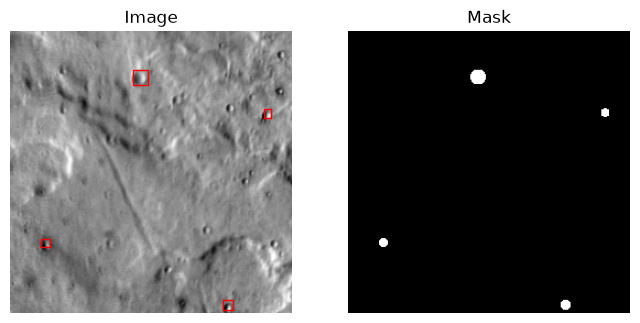

In [14]:
from matplotlib.patches import Rectangle


def make_mask(boxes):
    mask = np.zeros((256, 256), dtype=np.uint8)
    yy, xx = np.mgrid[0:256, 0:256]

    for x, y, w, h in boxes:
        cx = x + w / 2
        cy = y + h / 2
        r = max(w, h) / 2
        inside = (xx + 0.5 - cx) ** 2 + (yy + 0.5 - cy) ** 2 <= r ** 2
        mask[inside] = 1

    return mask


image_id = train_ids[0]
image = plt.imread(images_path / f"{image_id}.png")
mask = make_mask(data[image_id])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8, 4))

ax1.imshow(image, cmap="gray")
for x, y, w, h in data[image_id]:
    ax1.add_patch(Rectangle((x, y), w, h, fill=False, edgecolor="red", linewidth=1))
ax1.set_title("Image")
ax1.axis("off")

ax2.imshow(mask, cmap="gray")
ax2.set_title("Mask")
ax2.axis("off")

plt.show()

In [15]:
class CraterDataset(Dataset):
    def __init__(self, image_ids):
        self.image_ids = image_ids

    def __len__(self):
        return len(self.image_ids)

    def __getitem__(self, i):
        image_id = self.image_ids[i]

        image = Image.open(images_path / f"{image_id}.png").convert("L")
        image = torch.tensor(np.array(image), dtype=torch.float32) / 255.0
        image = image.unsqueeze(0)

        mask = make_mask(data[image_id])
        mask = torch.tensor(mask, dtype=torch.float32).unsqueeze(0)

        return image, mask


train_set = CraterDataset(train_ids)
val_set = CraterDataset(val_ids)
test_set = CraterDataset(test_ids)

train_loader = DataLoader(train_set, batch_size=16, shuffle=True)
val_loader = DataLoader(val_set, batch_size=16, shuffle=False)
test_loader = DataLoader(test_set, batch_size=16, shuffle=False)

images, masks = next(iter(train_loader))
print(images.shape)
print(masks.shape)

torch.Size([16, 1, 256, 256])
torch.Size([16, 1, 256, 256])


In [16]:
class PatchMLP(nn.Module):
    def __init__(self, patch=16):
        super().__init__()
        self.patch = patch
        self.mlp = nn.Sequential(
            nn.Linear(patch * patch, 512),
            nn.ReLU(),
            nn.Linear(512, 512),
            nn.ReLU(),
            nn.Linear(512, patch * patch),
        )

    def forward(self, x):
        b, p = x.shape[0], self.patch
        n = 256 // p

        # cut each image into 16 x 16 patches, flatten each patch
        x = x.view(b, n, p, n, p).permute(0, 1, 3, 2, 4).reshape(b * n * n, p * p)
        x = self.mlp(x)
        # put the patches back together into a 256 x 256 map
        x = x.view(b, n, n, p, p).permute(0, 1, 3, 2, 4).reshape(b, 1, 256, 256)
        return x

In [17]:
run_name = "01-patch16-constant-lr-10epochs"
run_dir = Path("src/mlp") / run_name
run_dir.mkdir(parents=True, exist_ok=True)

model = PatchMLP().to(device)
loss_fn = nn.BCEWithLogitsLoss(pos_weight=torch.tensor([10.0], device=device))
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

epochs = 10

In [18]:
cutoffs = [0.5]


def evaluate(model, loader):
    model.eval()
    total_loss, n = 0.0, 0
    intersection = {c: 0 for c in cutoffs}
    union = {c: 0 for c in cutoffs}

    with torch.no_grad():
        for images, masks in loader:
            images, masks = images.to(device), masks.to(device)

            outputs = model(images)
            total_loss += loss_fn(outputs, masks).item() * len(images)
            n += len(images)

            probs = torch.sigmoid(outputs)
            for c in cutoffs:
                preds = (probs > c).float()
                intersection[c] += (preds * masks).sum().item()
                union[c] += ((preds + masks) > 0).sum().item()

    ious = {c: intersection[c] / union[c] for c in cutoffs}
    best_cutoff = max(ious, key=ious.get)
    return total_loss / n, ious[best_cutoff], best_cutoff

In [21]:
import time
from tqdm import tqdm

history = {"train_loss": [], "val_loss": [], "val_iou": [], "best_cutoff": [], "lr": []}
best_iou = 0.0

for epoch in range(epochs):
    model.train()
    running_loss, n = 0.0, 0
    start = time.time()

    progress = tqdm(train_loader, desc=f"Epoch {epoch + 1}/{epochs}")
    for images, masks in progress:
        images, masks = images.to(device), masks.to(device)

        outputs = model(images)
        loss = loss_fn(outputs, masks)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * len(images)
        n += len(images)
        progress.set_postfix(loss=f"{running_loss / n:.4f}")

    train_loss = running_loss / n
    val_loss, val_iou, cutoff = evaluate(model, val_loader)
    lr = optimizer.param_groups[0]["lr"]

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["val_iou"].append(val_iou)
    history["best_cutoff"].append(cutoff)
    history["lr"].append(lr)
    (run_dir / "history.json").write_text(json.dumps(history))

    saved = ""
    if val_iou > best_iou:
        best_iou = val_iou
        torch.save(model.state_dict(), run_dir / "model.pt")
        saved = " (saved)"

    print(f"Epoch {epoch + 1}: train loss {train_loss:.4f} | val loss {val_loss:.4f}, "
          f"val IoU {val_iou:.4f} at cutoff {cutoff} | lr {lr:.6f} | {time.time() - start:.0f}s{saved}")

Epoch 1/10: 100%|██████████| 2592/2592 [01:17<00:00, 33.31it/s, loss=0.5565]


Epoch 1: train loss 0.5565 | val loss 0.5427, val IoU 0.1136 at cutoff 0.5 | lr 0.001000 | 87s (saved)


Epoch 2/10: 100%|██████████| 2592/2592 [01:12<00:00, 35.76it/s, loss=0.5106]


Epoch 2: train loss 0.5106 | val loss 0.4989, val IoU 0.1431 at cutoff 0.5 | lr 0.001000 | 81s (saved)


Epoch 3/10: 100%|██████████| 2592/2592 [01:13<00:00, 35.46it/s, loss=0.4916]


...

Epoch 8: train loss 0.4666 | val loss 0.4741, val IoU 0.1623 at cutoff 0.5 | lr 0.001000 | 82s


Epoch 9/10: 100%|██████████| 2592/2592 [01:13<00:00, 35.46it/s, loss=0.4644]


Epoch 9: train loss 0.4644 | val loss 0.4825, val IoU 0.1497 at cutoff 0.5 | lr 0.001000 | 82s


Epoch 10/10: 100%|██████████| 2592/2592 [01:13<00:00, 35.37it/s, loss=0.4623]


Epoch 10: train loss 0.4623 | val loss 0.4657, val IoU 0.1786 at cutoff 0.5 | lr 0.001000 | 82s


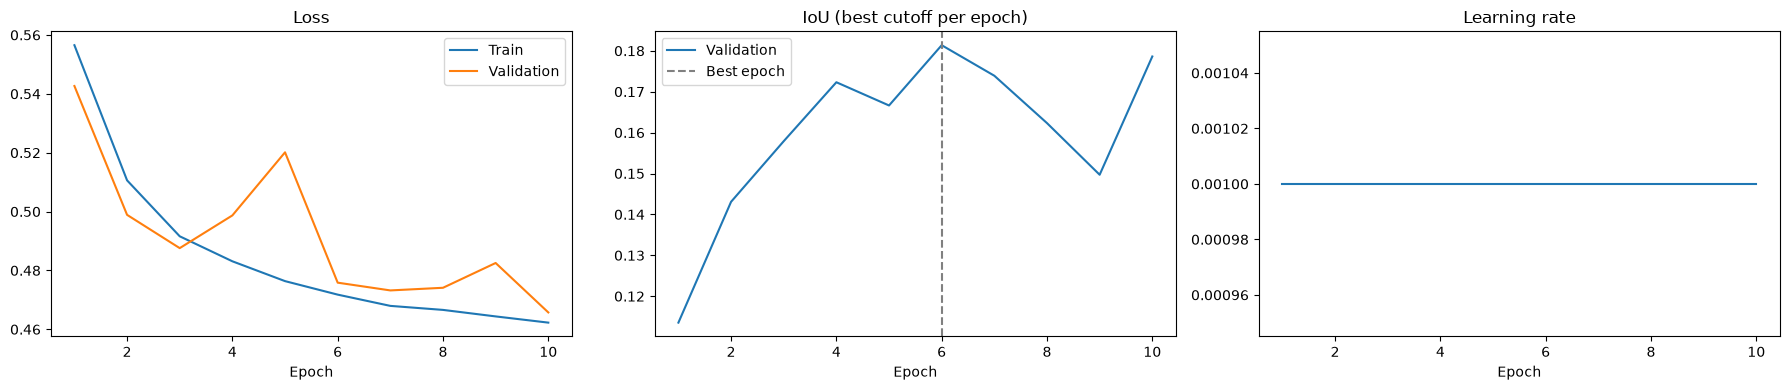

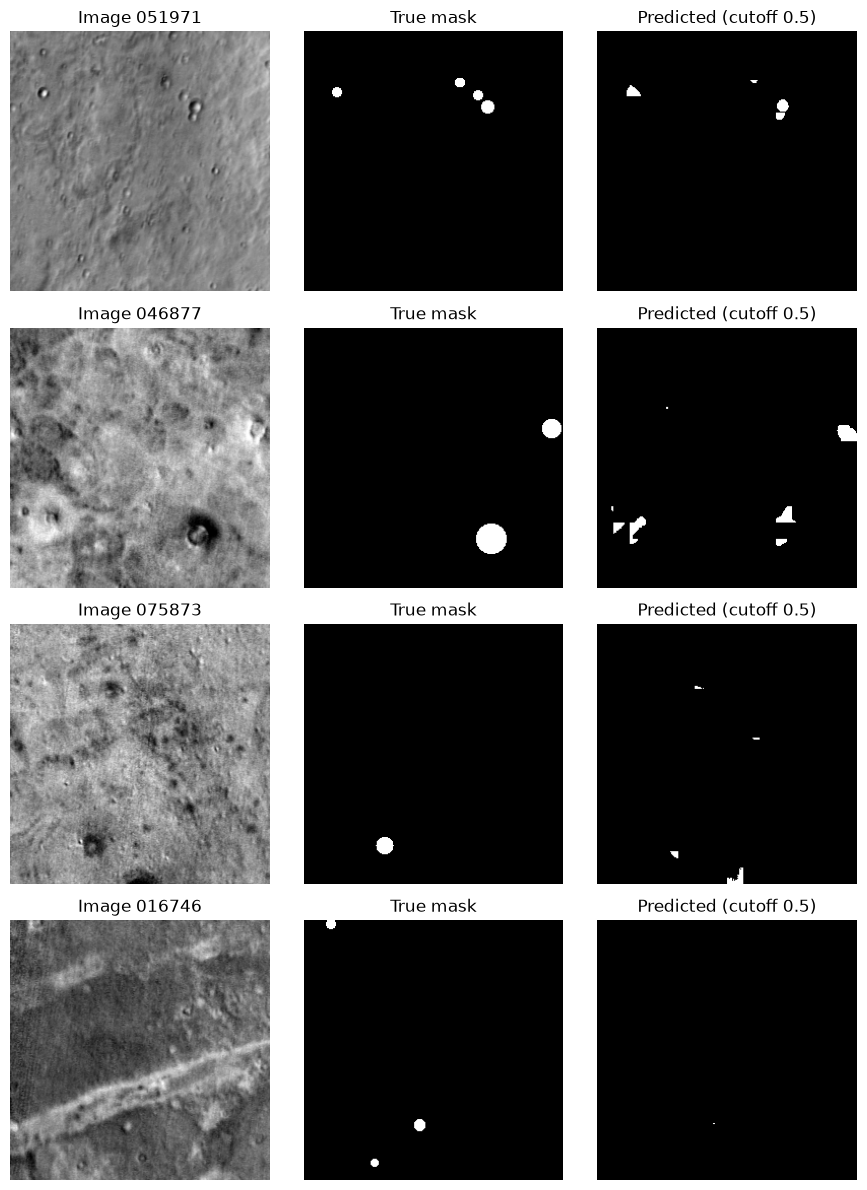

In [23]:
# 1. Notes
best_epoch = history["val_iou"].index(max(history["val_iou"]))
best_cutoff = history["best_cutoff"][best_epoch]

notes = f"""model: PatchMLP (16 x 16 patches, 256-512-512-256), 525,568 parameters
loss: BCEWithLogitsLoss, pos_weight=10
optimizer: Adam, lr=1e-3, constant, no weight decay
batch size: 16
epochs: 10
cutoff: 0.5
best epoch: {best_epoch + 1}
best val IoU: {history["val_iou"][best_epoch]:.4f} at cutoff {best_cutoff}
"""

(run_dir / "notes.txt").write_text(notes)

# 2. Loss, IoU, and learning rate curves
epochs_range = range(1, len(history["train_loss"]) + 1)

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 4))

ax1.plot(epochs_range, history["train_loss"], label="Train")
ax1.plot(epochs_range, history["val_loss"], label="Validation")
ax1.set_title("Loss")
ax1.set_xlabel("Epoch")
ax1.legend()

ax2.plot(epochs_range, history["val_iou"], label="Validation")
ax2.axvline(best_epoch + 1, linestyle="--", color="gray", label="Best epoch")
ax2.set_title("IoU (best cutoff per epoch)")
ax2.set_xlabel("Epoch")
ax2.legend()

ax3.plot(epochs_range, history["lr"])
ax3.set_title("Learning rate")
ax3.set_xlabel("Epoch")

plt.tight_layout()
plt.savefig(run_dir / "curves.png", dpi=150, bbox_inches="tight")
plt.show()

# 3. Example predictions from the best saved model
model.load_state_dict(torch.load(run_dir / "model.pt", map_location=device))
model.eval()

fig, axes = plt.subplots(4, 3, figsize=(9, 12))

for i, row in enumerate(axes):
    image, mask = val_set[i]
    with torch.no_grad():
        pred = torch.sigmoid(model(image.unsqueeze(0).to(device)))
    pred = (pred > best_cutoff).float().squeeze().cpu()

    row[0].imshow(image.squeeze(), cmap="gray")
    row[0].set_title(f"Image {val_ids[i]}")
    row[1].imshow(mask.squeeze(), cmap="gray")
    row[1].set_title("True mask")
    row[2].imshow(pred, cmap="gray")
    row[2].set_title(f"Predicted (cutoff {best_cutoff})")
    for ax in row:
        ax.axis("off")

plt.tight_layout()
plt.savefig(run_dir / "predictions.png", dpi=150, bbox_inches="tight")
plt.show()